In [55]:
from __future__ import annotations

import operator
from typing import TypedDict, List, Annotated

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

# from langchain_openai import ChatOpenAI
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage
import os

In [56]:
class Task(BaseModel):
    id: int
    title: str
    brief: str = Field(..., description="What to cover")

In [57]:
class Plan(BaseModel):
    blog_title: str
    tasks: List[Task]

In [58]:
class State(TypedDict):
    topic: str
    plan: Plan
    # reducer: results from workers get concatenated automatically
    sections: Annotated[List[str], operator.add]
    final: str

In [59]:
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,    
    api_key=os.getenv("GROQ_API_KEY"),
)

In [60]:
def orchestrator(state: State) -> dict:

    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(
                content=(
                    "Create a blog plan with 5-7 sections on the following topic."
                )
            ),
            HumanMessage(content=f"Topic: {state['topic']}"),
        ]
    )
    return {"plan": plan}

In [61]:
def fanout(state: State):
    return [Send("worker", {"task": task, "topic": state["topic"], "plan": state["plan"]})
            for task in state["plan"].tasks]

In [62]:
def worker(payload: dict) -> dict:

    # payload contains what we sent
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section."),
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            ),
        ]
    ).content.strip()

    return {"sections": [section_md]}

In [63]:

from pathlib import Path
import re

def reducer(state: State) -> dict:

    print("\n========== REDUCER STARTED ==========")

    # Get blog title and generated sections
    title = state["plan"].blog_title
    sections = state["sections"]

    print("Blog title:", title)
    print("Number of sections received:", len(sections))

    # Combine all sections
    body = "\n\n".join(sections).strip()

    # Generate complete Markdown content
    final_md = f"# {title}\n\n{body}\n"

    print("Markdown content length:", len(final_md))

    # Create output directory
    output_dir = Path.cwd() / "generated_blogs"
    output_dir.mkdir(parents=True, exist_ok=True)

    # Generate a safe filename
    filename = re.sub(r'[^\w\-]', '_', title.lower()).strip('_') + ".md"

    # Create complete file path
    output_path = output_dir / filename

    # Write Markdown content to file
    output_path.write_text(final_md, encoding="utf-8")

    # Verify file creation
    if output_path.exists() and output_path.stat().st_size > 0:
        print("\nSUCCESS! Blog saved successfully.")
        print("File location:", output_path.resolve())
        print("File size:", output_path.stat().st_size, "bytes")
    else:
        print("\nERROR: File was not saved correctly.")

    print("========== REDUCER FINISHED ==========\n")

    return {"final": final_md}


In [64]:
g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

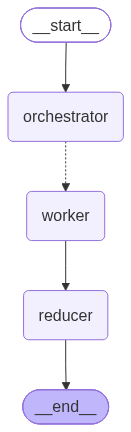

In [65]:
g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()

app

In [66]:
out = app.invoke({"topic": "Write a blog on Self Attention", "sections": []})


========== REDUCER STARTED ==========
Blog title: Demystifying Self-Attention: From Theory to Practice
Number of sections received: 6
Markdown content length: 28922

SUCCESS! Blog saved successfully.
File location: D:\Langraph\Blog Writing Agent\generated_blogs\demystifying_self-attention__from_theory_to_practice.md
File size: 30261 bytes
========== REDUCER FINISHED ==========



In [53]:
print(out['final'])

# Demystifying Self-Attention: From Theory to Practice

## Introduction – Why Self‑Attention Matters

In the last few years, **attention mechanisms** have reshaped the landscape of artificial intelligence. From the first glimpse of “soft” attention in neural machine translation to the explosive success of Transformer‑based models, attention has become the engine that powers everything from language understanding to computer vision and protein folding.

### The rise of attention

- **From sequence‑to‑sequence to Transformers** – Early sequence models (RNNs, LSTMs) struggled with long‑range dependencies. The introduction of attention allowed models to “look back” at any part of the input, dramatically improving translation quality and training speed.  
- **Scalability and parallelism** – Unlike recurrent architectures, attention can be computed in parallel across all positions, enabling the massive scaling that underlies GPT‑4, BERT, and their successors.  
- **Cross‑domain versatility**